In [1]:
library(dplyr)
library(Seurat)
library(ggplot2)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.




In [2]:
prechemo <- readRDS('../Results/PreChemo/prechemo_annotated.rds')

In [3]:
prechemo

An object of class Seurat 
27209 features across 8020 samples within 2 assays 
Active assay: RNA (25209 features, 2000 variable features)
 3 layers present: scale.data, data, counts
 1 other assay present: integrated
 2 dimensional reductions calculated: pca, umap

In [4]:
colnames(prechemo@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample_id"              "percent.mt"             "percent.eryth"         
 [7] "treatment"              "integrated_snn_res.0.3" "seurat_clusters"       
[10] "cell_type"

In [5]:
unique(prechemo$sample_id)

[1] "GSM6204109_P01" "GSM6204110_P02"

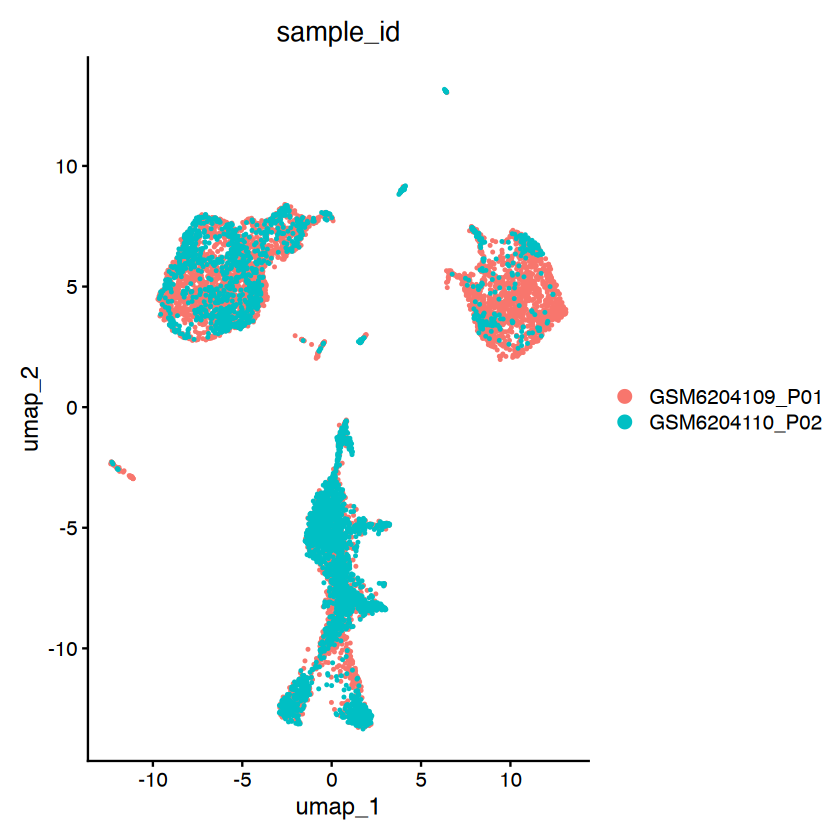

In [6]:
DimPlot(prechemo, group.by = 'sample_id')

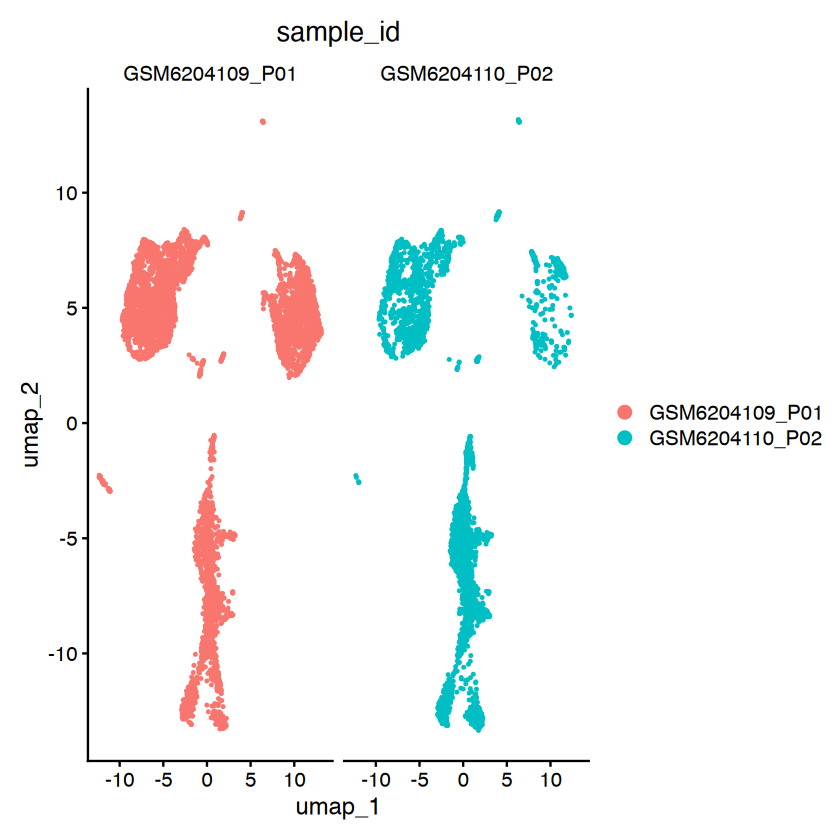

In [7]:
DimPlot(prechemo, group.by = 'sample_id', split.by='sample_id')

In [8]:
cell_type_markers <- list(
  "T/NK" = c("CCL5", "GNLY", "NKG7", "CCL4", "IL7R"),

  "Epithelial" = c("TFF1", "LCN2", "KRT19", "SPINK1", "TFF2"),

  "Endothelial" = c("SPARCL1", "ACKR1", "CCL14", "VWF", "COL4A1"),

  "Myeloid" = c("SPP1", "APOE", "S100A9", "IFI30", "HLA-DRA"),

  "Prolif. epithelial" = c("UBE2C", "AKR1C2", "UBE2S", "CCNB1", "S100A2"),

  "Prolif. lymphoid" = c("HIST1H4C", "HMGB2", "STMN1", "MKI67", "CENPF"),

  "B/Plasma" = c("IGKC", "IGLC2", "IGHG1", "IGLC3", "IGLC1"),

  "Prolif. myeloid" = c("MMP9", "CTSK", "ACP5", "CST3", "RGS10"),

  "CAFs" = c("COL3A1", "COL1A2", "COL1A1", "SFRP2", "DCN"),

  "Mast" = c("TPSAB1", "TPSB2", "CPA3", "MS4A2", "KIT")
)

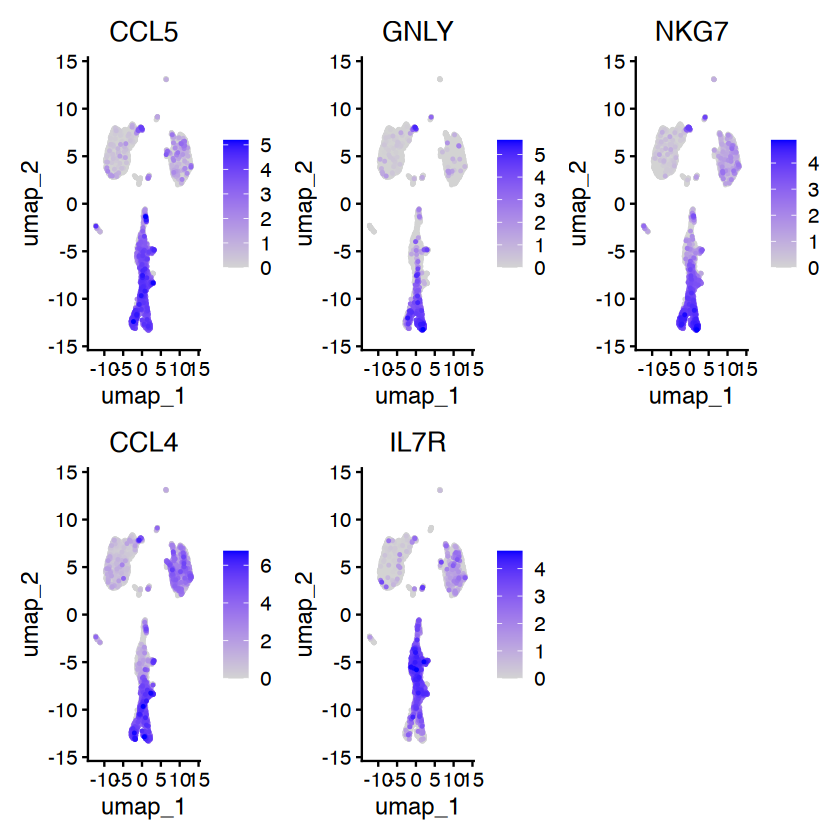

In [9]:
DefaultAssay(prechemo) <- "RNA"

FeaturePlot(
  object = prechemo,
  features = cell_type_markers[["T/NK"]],
  reduction = "umap",
  ncol = 3,
  order = TRUE
)

Warning message in DoHeatmap(object = prechemo, features = markers, assay = "RNA", :
“The following features were omitted as they were not found in the scale.data layer for the RNA assay: RGS10, CST3, CTSK, AKR1C2”
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


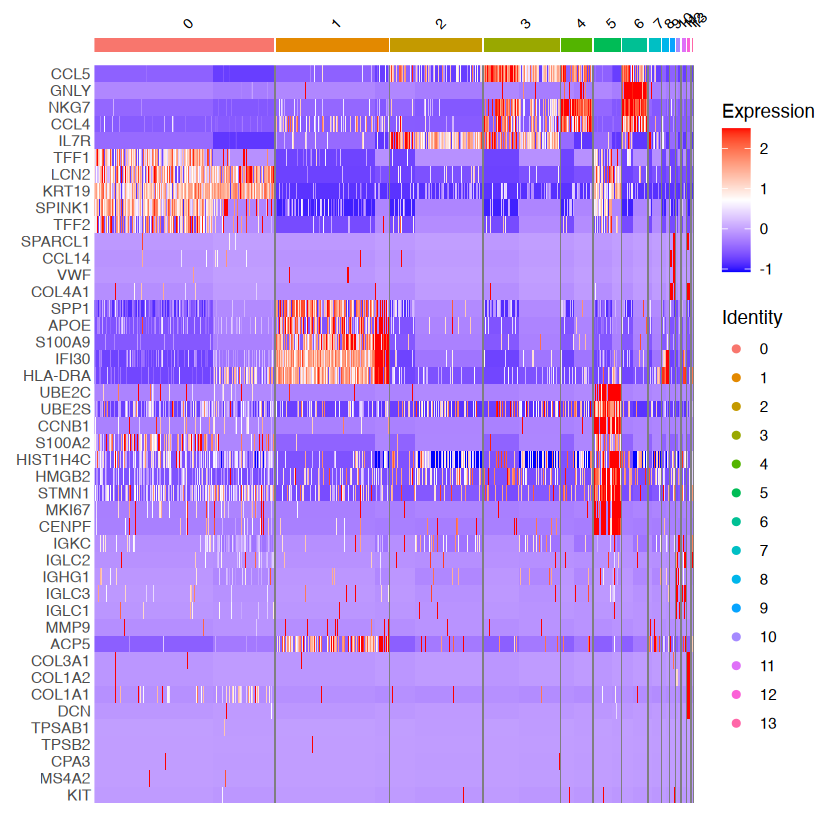

In [10]:
DefaultAssay(prechemo) <- "RNA"

markers <- unlist(cell_type_markers, use.names = FALSE)

# Keep available genes
markers <- markers[markers %in% rownames(prechemo)]

# Plot heatmap
DoHeatmap(
  object = prechemo,
  features = markers,
  assay = "RNA",
  slot = "scale.data",
  group.by = NULL,
  disp.min = -2.5,
  disp.max = 2.5,
  size = 3,
  raster = TRUE
) +
  scale_fill_gradientn(
    colors = c("blue", "white", "red")
  ) +
  theme(
    axis.text.x = element_blank(),
    axis.text.y = element_text(size = 9)
  )



In [11]:
markers

[1] "CCL5"     "GNLY"     "NKG7"     "CCL4"     "IL7R"     "TFF1"    
 [7] "LCN2"     "KRT19"    "SPINK1"   "TFF2"     "SPARCL1"  "CCL14"   
[13] "VWF"      "COL4A1"   "SPP1"     "APOE"     "S100A9"   "IFI30"   
[19] "HLA-DRA"  "UBE2C"    "AKR1C2"   "UBE2S"    "CCNB1"    "S100A2"  
[25] "HIST1H4C" "HMGB2"    "STMN1"    "MKI67"    "CENPF"    "IGKC"    
[31] "IGLC2"    "IGHG1"    "IGLC3"    "IGLC1"    "MMP9"     "CTSK"    
[37] "ACP5"     "CST3"     "RGS10"    "COL3A1"   "COL1A2"   "COL1A1"  
[43] "DCN"      "TPSAB1"   "TPSB2"    "CPA3"     "MS4A2"    "KIT"

In [12]:
options(repr.plot.width = 20, repr.plot.height = 7)

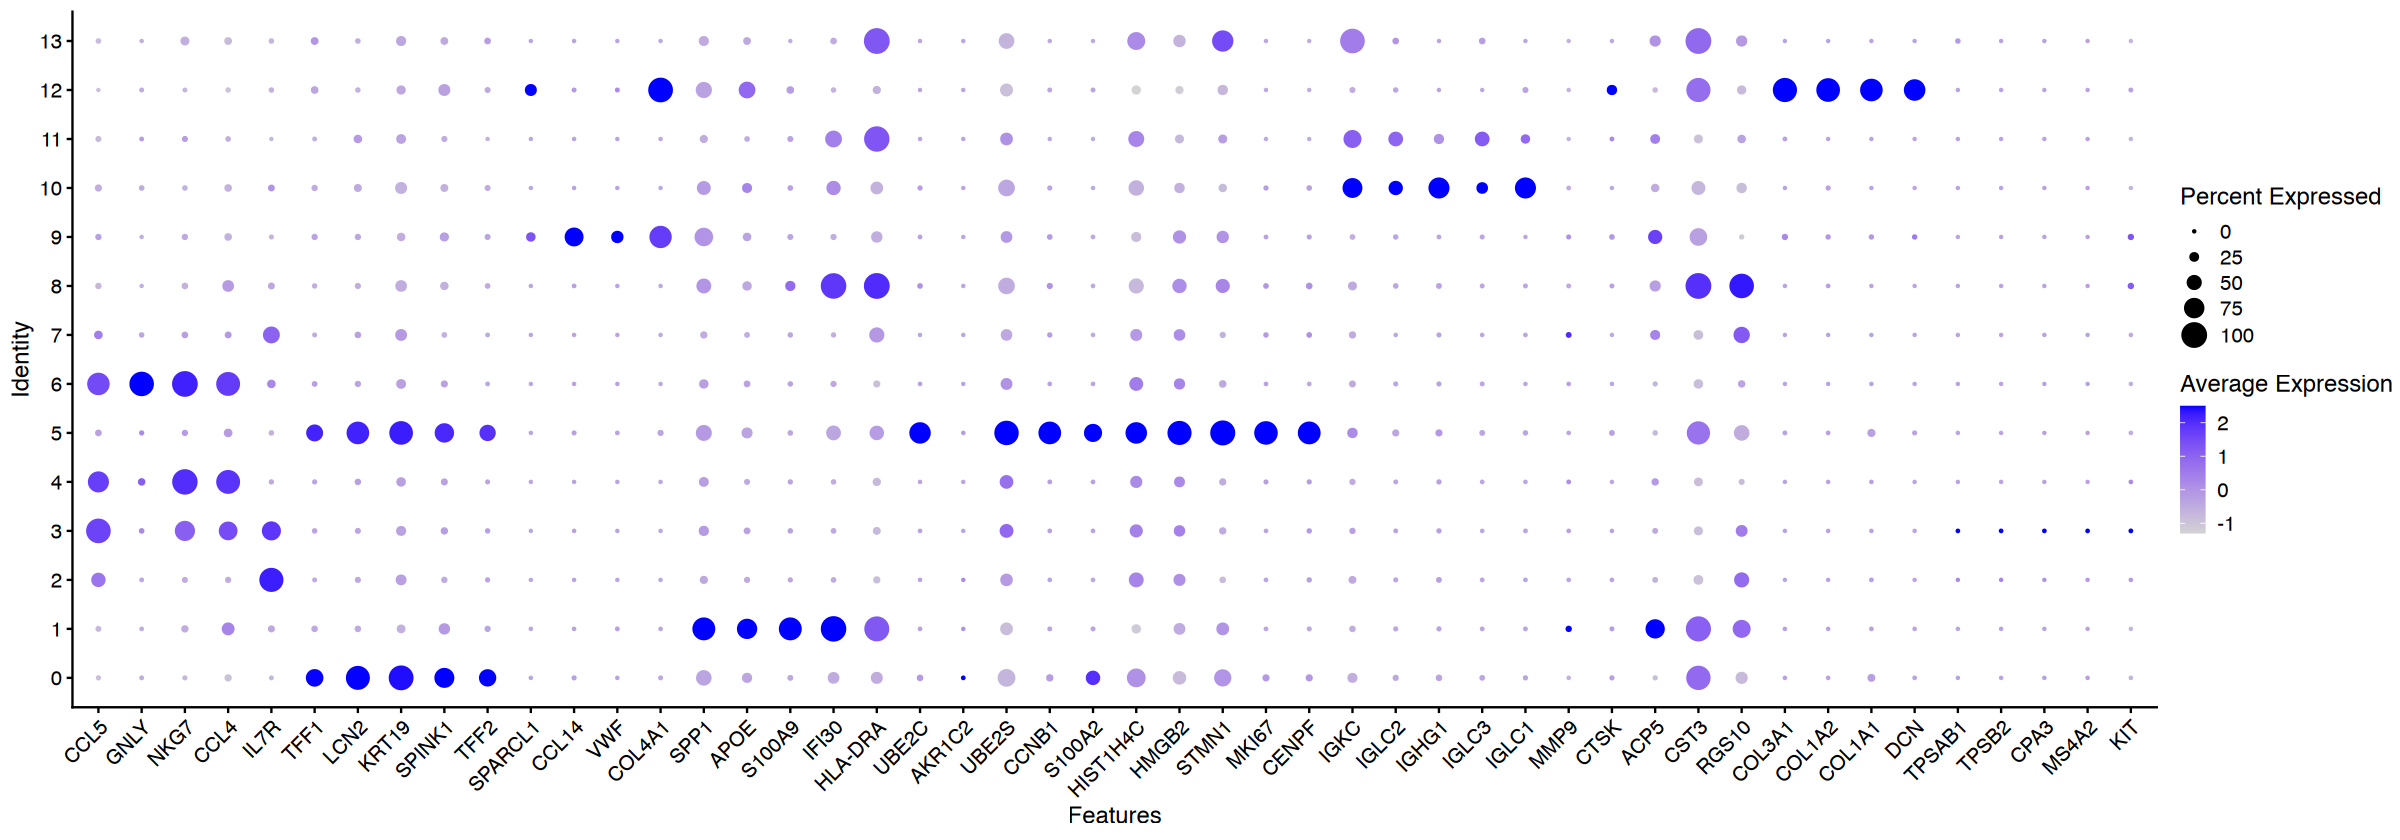

In [13]:
DotPlot(prechemo, features = markers) + RotatedAxis()

In [14]:
# Subset cluster 5 from the prechemo Seurat object
cluster5_prechemo <- subset(prechemo, idents = 5)

In [15]:
cluster5_prechemo <- FindVariableFeatures(cluster5_prechemo, selection.method = "vst", nfeatures = 2000)

Finding variable features for layer counts



In [16]:
cluster5_prechemo <- ScaleData(cluster5_prechemo)

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”


In [17]:
cluster5_prechemo <- RunPCA(cluster5_prechemo, npcs = 30)

PC_ 1 
Positive:  VCP, KLK8, NUDT2, TNFRSF6B, DUSP27, HDGFL3, KLK6, MDFI, PMEPA1, BMP4 
	   COL6A1, PCDH7, TRIB2, STOML2, AQP5, ALPG, TGFBI, TLN1, SMURF2, SMAD6 
	   CREB3, CFB, AHNAK2, CAVIN3, NRP2, PIGO, PRRX2, TESK1, TPM2, MUC16 
Negative:  CDKN2A, SPINK1, LGALS4, CLDN18, LGALS7B, LDHB, CXCL17, TFF1, PTGIS, ANXA10 
	   COTL1, SPTSSB, FTL, TOMM5, LGALS7, LINC01133, EIF5A, TM4SF18, TFF2, MGST1 
	   DMKN, S100A2, VNN1, PIGR, VSIG1, LGALS2, GSTM3, RFLNA, CA2, CAVIN1 
PC_ 2 
Positive:  PTPRC, SRGN, LCP1, CORO1A, SEPTIN6, LSP1, PTPN7, CD52, EVL, GMFG 
	   P2RY10, APBB1IP, CELF2, IL2RG, DOCK8, CD53, DOCK2, FYB1, HCST, TRBC2 
	   CYTIP, TRAC, GNG2, MSN, ITM2A, CD2, ITGA4, SLA, CLEC2D, CD3E 
Negative:  KRT19, TSPAN8, LGALS4, LCN2, CLDN18, SPINK1, S100A16, STARD10, MGST1, CAMK2N1 
	   CEACAM6, MDK, CXCL17, TFF1, FTL, PTGIS, LGALS7B, PHLDA2, CDKN2A, TPM1 
	   CST3, TMC5, ANXA10, SPTSSB, GSTM3, MUC5AC, SLC44A4, TM4SF18, ARL14, LINC01133 
PC_ 3 
Positive:  IGSF6, MS4A4A, MAFB, C1QC, PTPRO, MS4A6

In [18]:
cluster5_prechemo <- FindNeighbors(cluster5_prechemo, dims=1:30)

Computing nearest neighbor graph

Computing SNN



In [19]:
cluster5_prechemo <- FindClusters(cluster5_prechemo, resolution=1.5, algorithm=3)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 378
Number of edges: 12187

Running smart local moving algorithm...
Maximum modularity in 10 random starts: 0.5907
Number of communities: 6
Elapsed time: 0 seconds


In [20]:
cluster5_prechemo <- RunUMAP(cluster5_prechemo, dims=1:30, n.neighbors = 30, min.dist = 0.3)

16:23:43 UMAP embedding parameters a = 0.9922 b = 1.112

16:23:43 Read 378 rows and found 30 numeric columns

16:23:43 Using Annoy for neighbor search, n_neighbors = 30

16:23:43 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:23:43 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//RtmpxbCCvs/file40b13ee58c93

16:23:43 Searching Annoy index using 1 thread, search_k = 3000

16:23:43 Annoy recall = 100%

16:23:43 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:23:44 Initializing from normalized Laplacian + noise (using RSpectra)

16:23:44 Commencing optimization for 500 epochs, with 14608 positive edges

16:23:44 Using rng type: pcg

16:23:44 Optimization finished



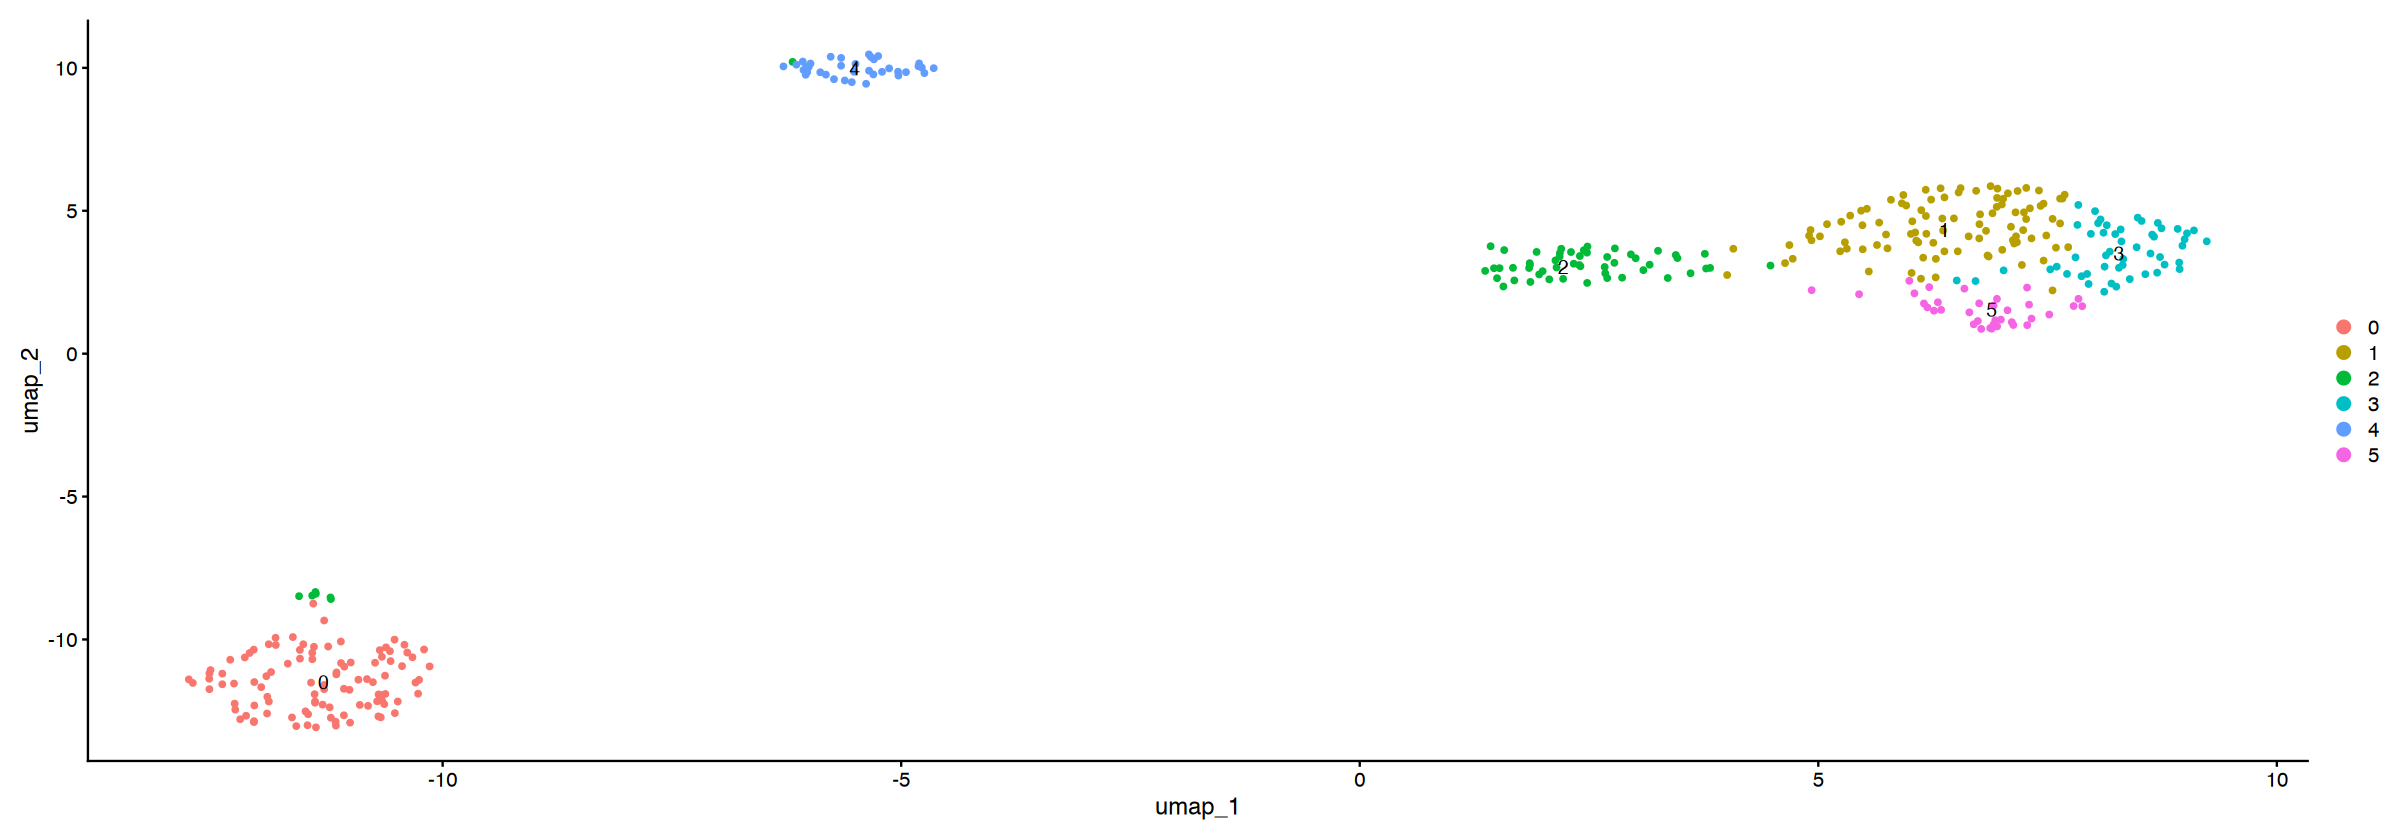

In [21]:
DimPlot(cluster5_prechemo, reduction = "umap", label = TRUE)

In [22]:
DefaultAssay(cluster5_prechemo) <- "RNA"

In [23]:
cluster5_prechemo_markers <- FindAllMarkers(
  cluster5_prechemo,
  only.pos = TRUE,
  min.pct = 0.1,
  logfc.threshold = 0.25
)

Calculating marker statistics for 6 clusters using presto

  Calculating fold changes

  Running presto::wilcoxauc



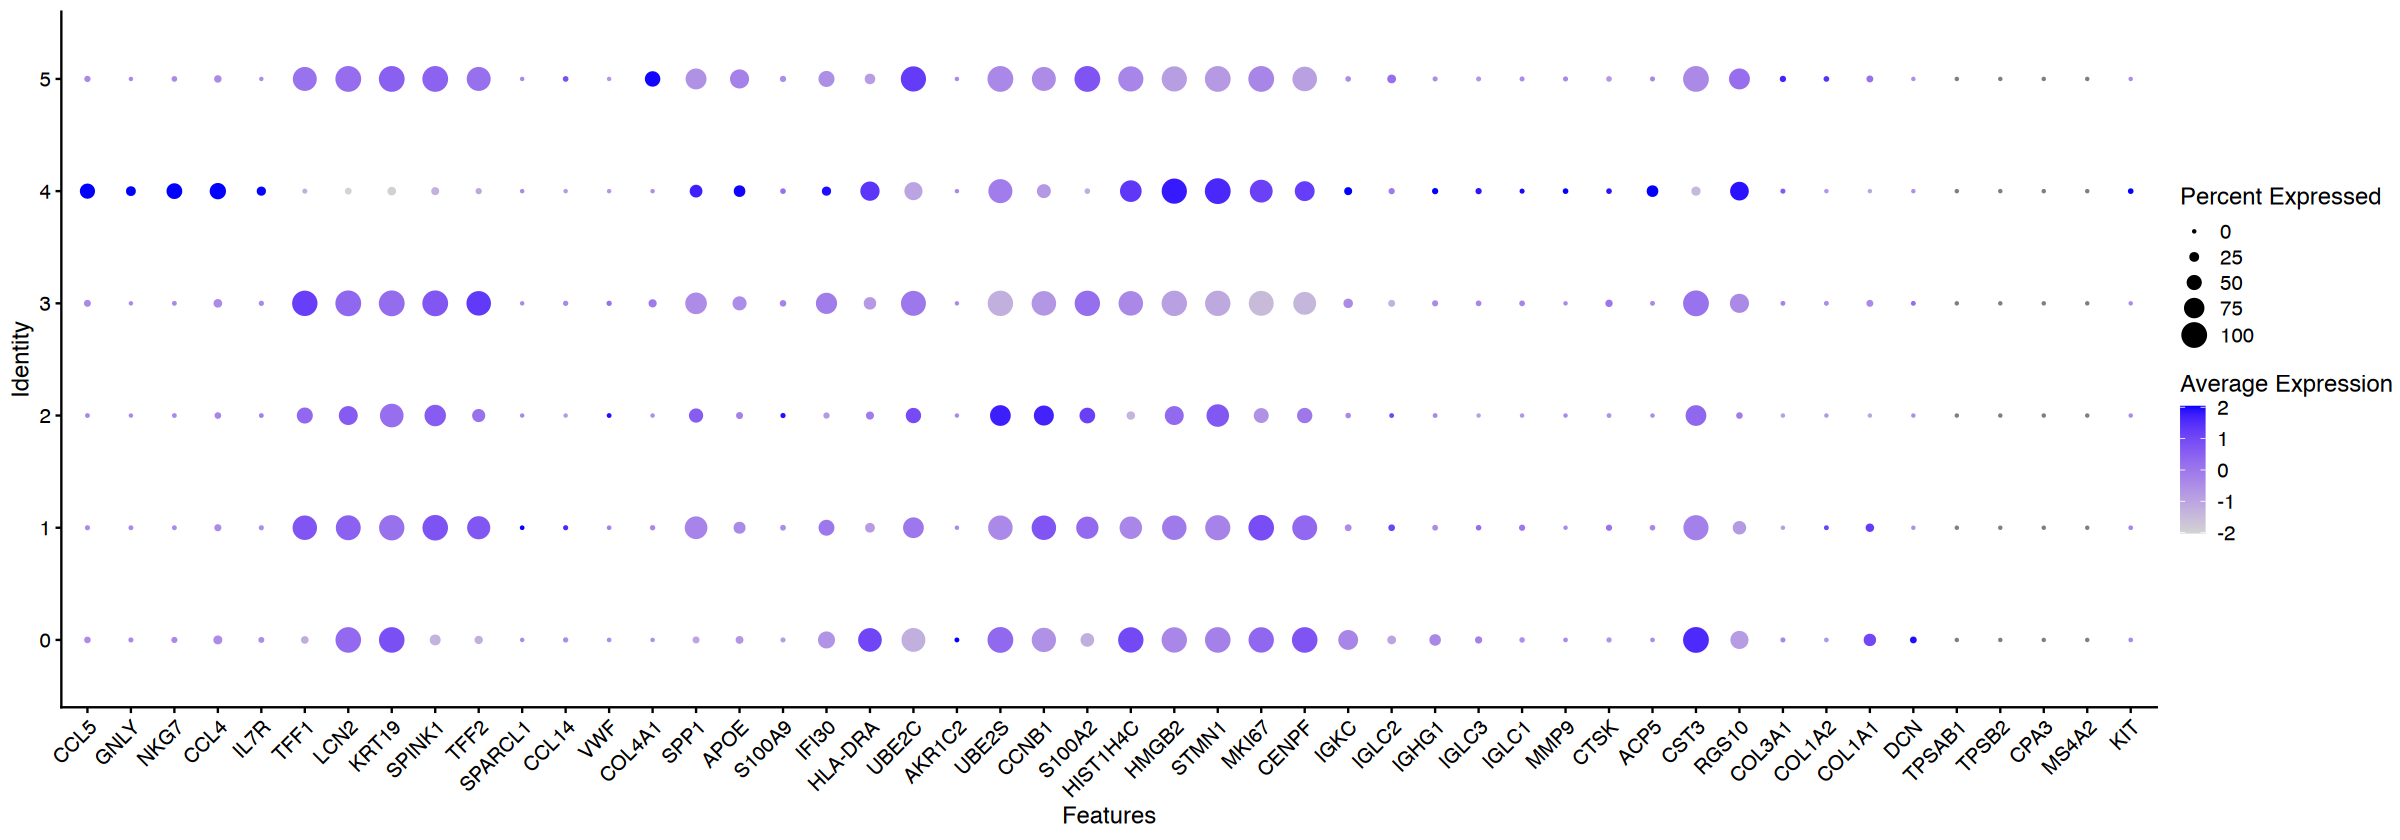

In [24]:
DotPlot(cluster5_prechemo, features = markers) + RotatedAxis()

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”


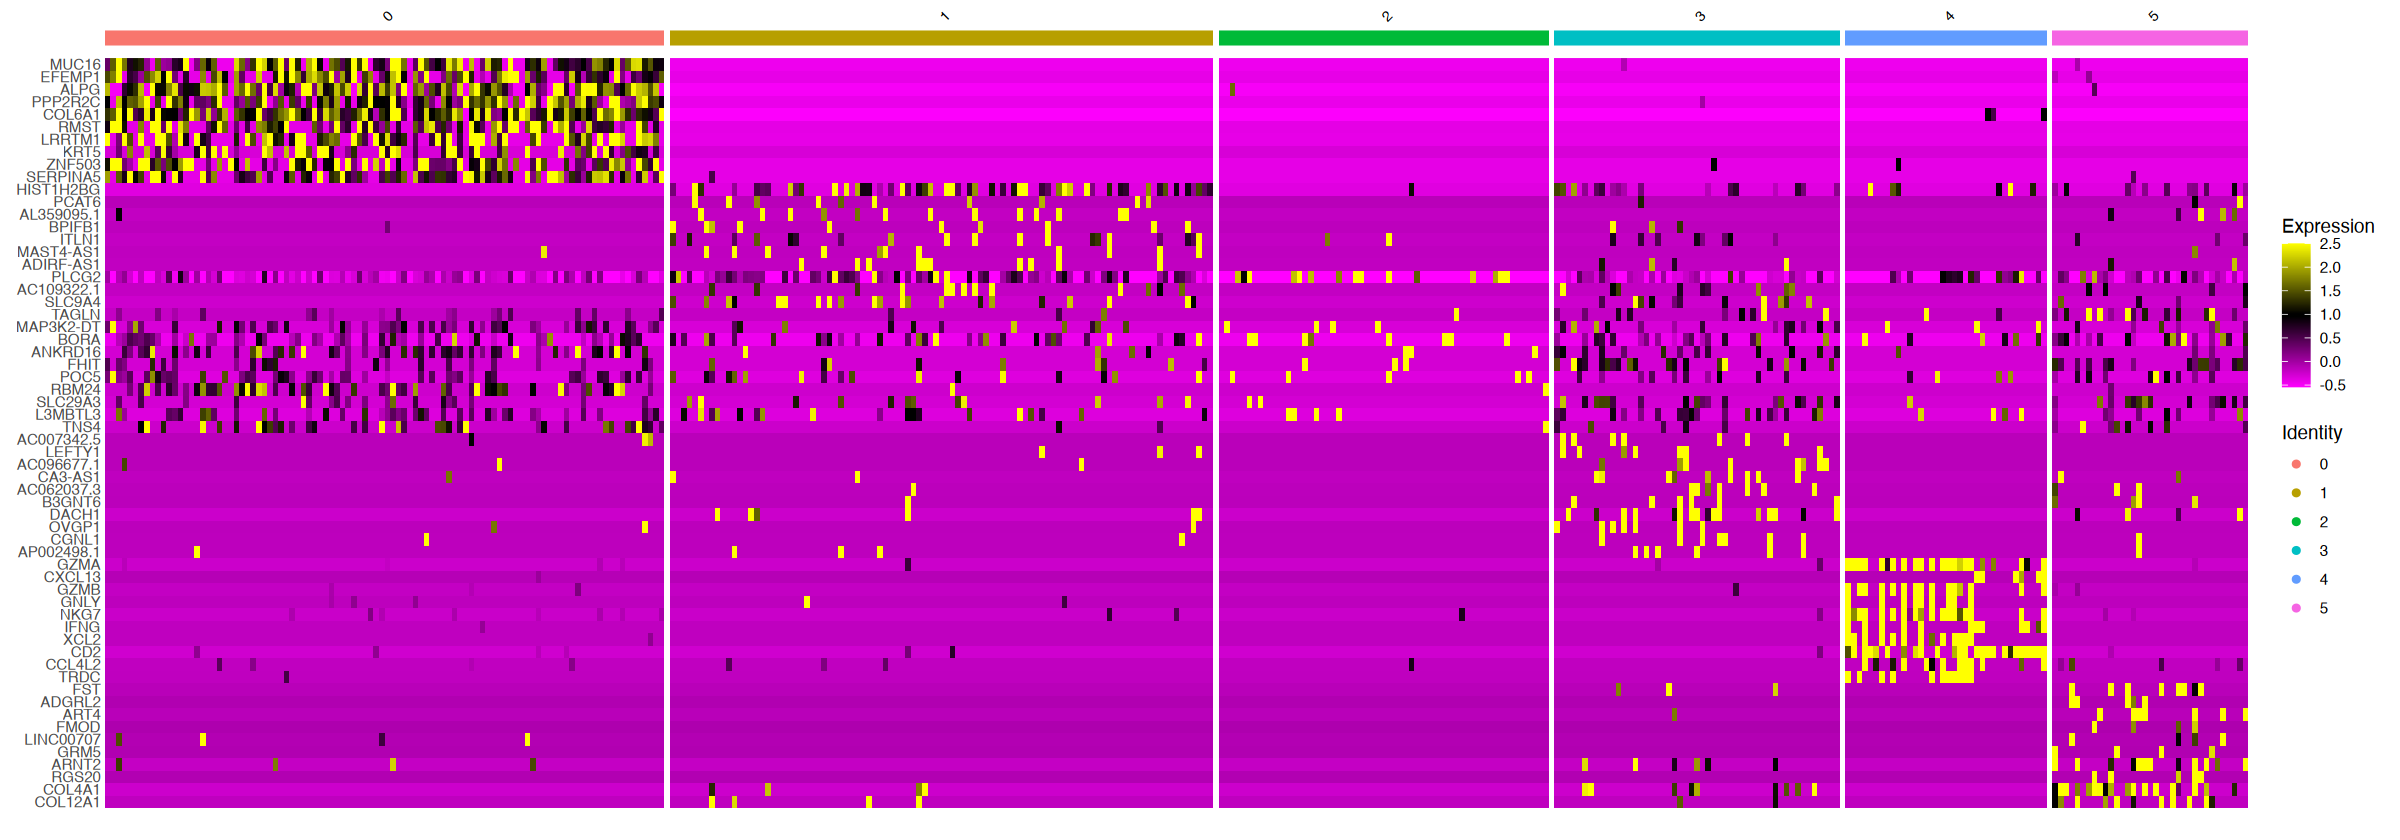

In [25]:
top10 <- cluster5_prechemo_markers %>%
  group_by(cluster) %>%
  slice_max(avg_log2FC, n = 10, with_ties = FALSE)

cluster5_prechemo <- ScaleData(
  cluster5_prechemo,
  features = unique(top10$gene)
)

DoHeatmap(
  cluster5_prechemo,
  features = unique(top10$gene),
  size = 3
)



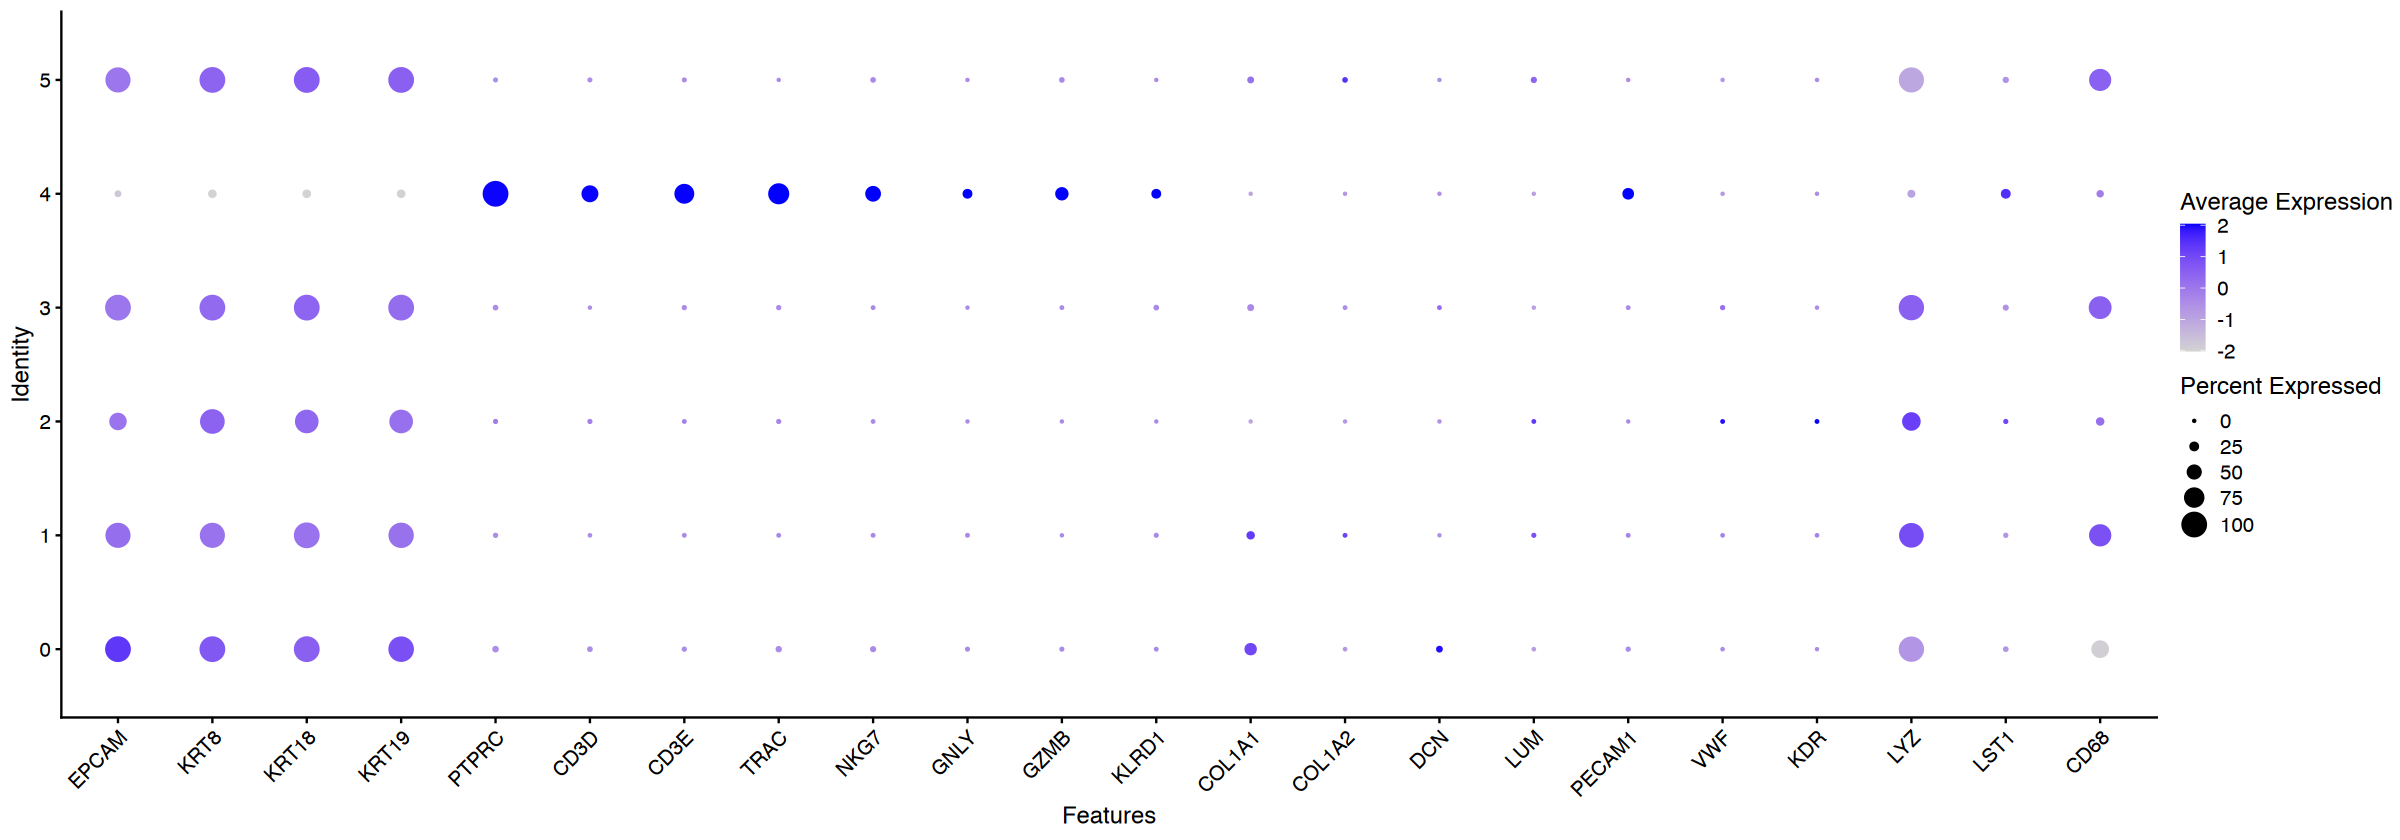

In [28]:
lineage_markers <- c(
  "EPCAM", "KRT8", "KRT18", "KRT19",   # Epithelial
  "PTPRC", "CD3D", "CD3E", "TRAC",    # Immune/T cells
  "NKG7", "GNLY", "GZMB", "KLRD1",    # Cytotoxic T/NK
  "COL1A1", "COL1A2", "DCN", "LUM",   # Fibroblasts
  "PECAM1", "VWF", "KDR",             # Endothelial
  "LYZ", "LST1", "CD68"              # Myeloid
)

DotPlot(
  cluster5_prechemo,
  features = lineage_markers
) + RotatedAxis()

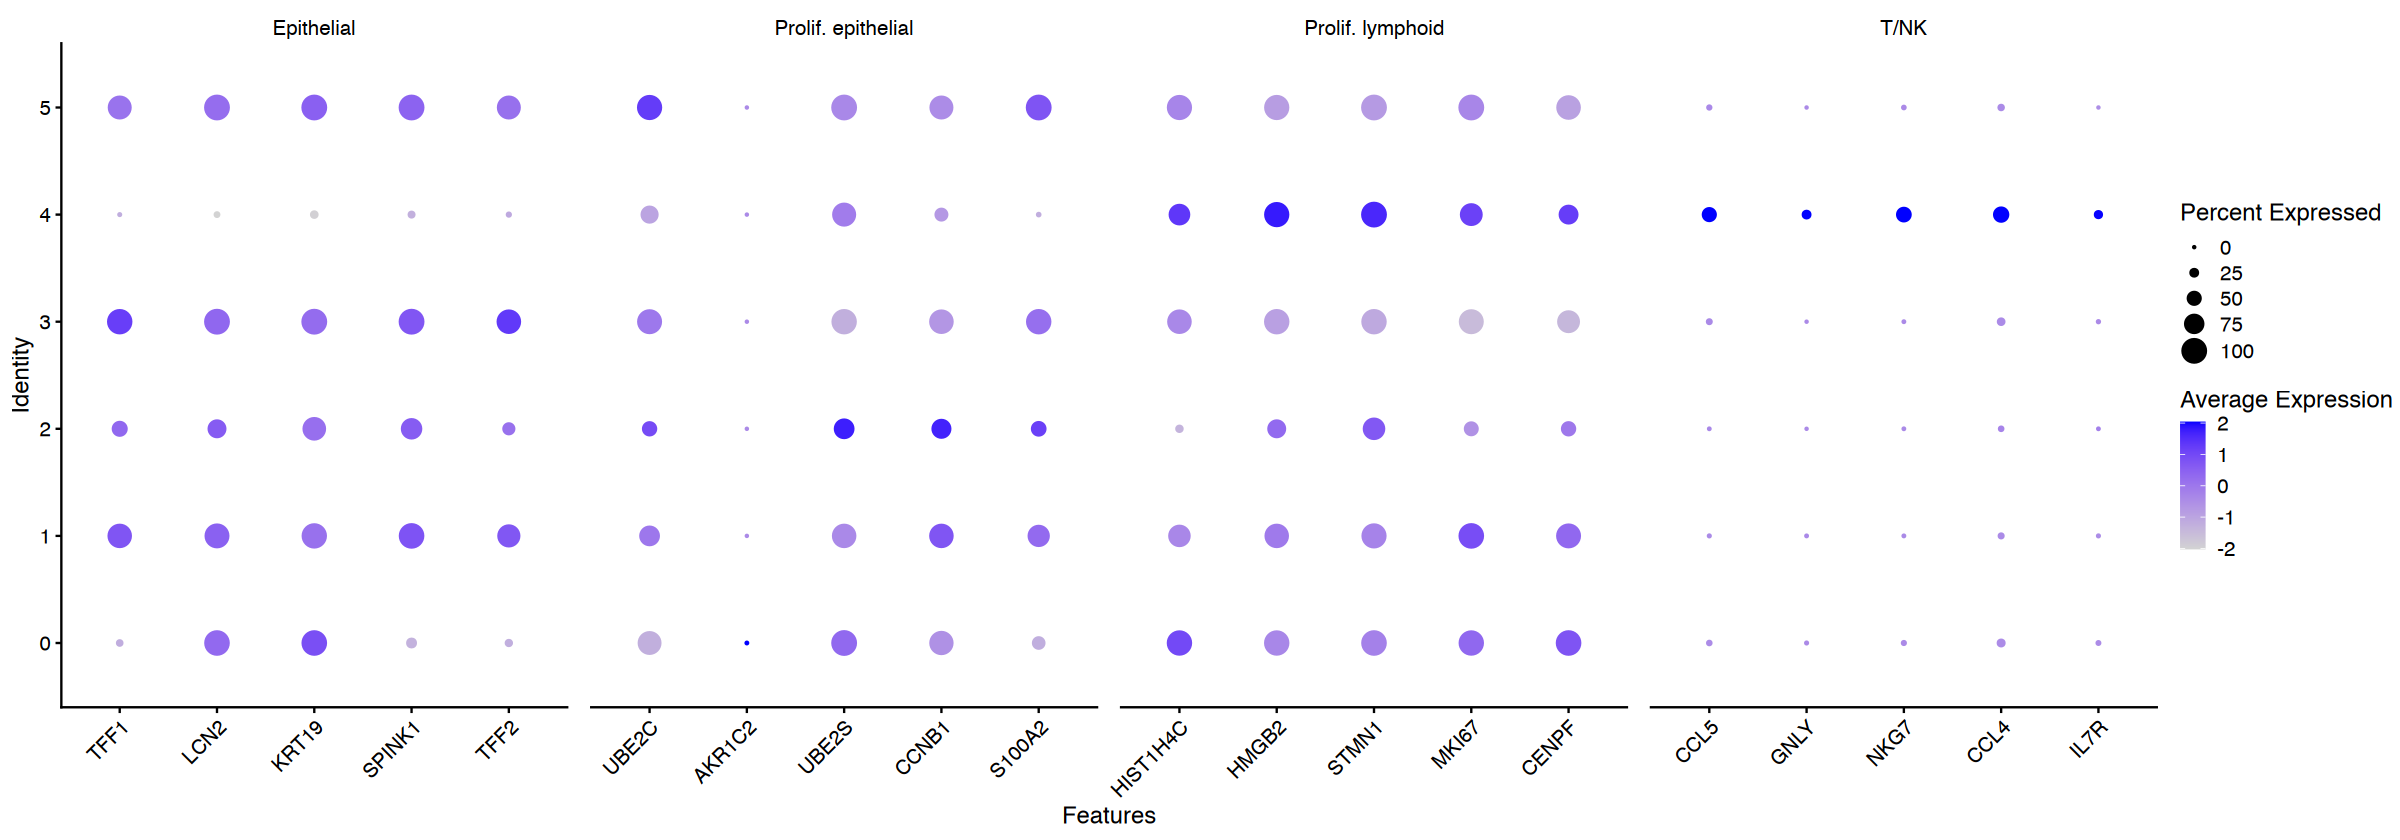

In [29]:
DotPlot(
  cluster5_prechemo,
  features = list(
    "Epithelial" = cell_type_markers[["Epithelial"]],
    "Prolif. epithelial" = cell_type_markers[["Prolif. epithelial"]],
    "Prolif. lymphoid" = cell_type_markers[["Prolif. lymphoid"]],
    "T/NK" = cell_type_markers[["T/NK"]]
  )
) + RotatedAxis()

In [30]:
# Original cluster annotations
original_annotations <- c(
  "0"  = "Epithelial",
  "1"  = "Myeloid",
  "2"  = "T/NK",
  "3"  = "T/NK",
  "4"  = "T/NK",
  "5"  = "Unassigned",
  "6"  = "T/NK",
  "7"  = "T/NK",
  "8"  = "Myeloid",
  "9"  = "Endothelial",
  "10" = "B/Plasma",
  "11" = "Myeloid",
  "12" = "CAFs",
  "13" = "Proliferating - unresolved"
)

# Add cell type annotations using original cluster IDs
prechemo$cell_type_refined <- unname(
  original_annotations[as.character(prechemo$seurat_clusters)]
)

In [31]:
cluster5_annotations <- c(
  "0" = "Prolif. epithelial",
  "1" = "Epithelial",
  "2" = "Prolif. epithelial",
  "3" = "Epithelial",
  "4" = "Prolif. lymphoid",
  "5" = "Epithelial"
)

# Add annotations to the subset
cluster5_prechemo$cell_type_refined <- unname(
  cluster5_annotations[as.character(Idents(cluster5_prechemo))]
)

In [32]:
# Identify cells belonging to original cluster 5
cluster5_cells <- colnames(cluster5_prechemo)

# Confirm that all subset cells exist in the original object
stopifnot(all(cluster5_cells %in% colnames(prechemo)))

# Replace original cluster 5 annotations
prechemo$cell_type_refined[cluster5_cells] <-
  cluster5_prechemo$cell_type_refined[cluster5_cells]

# Check annotations
table(prechemo$cell_type_refined, useNA = "ifany")


                  B/Plasma                       CAFs 
                        54                         40 
               Endothelial                 Epithelial 
                        68                       2671 
                   Myeloid         Prolif. epithelial 
                      1710                        159 
          Prolif. lymphoid Proliferating - unresolved 
                        36                         19 
                      T/NK 
                      3263 

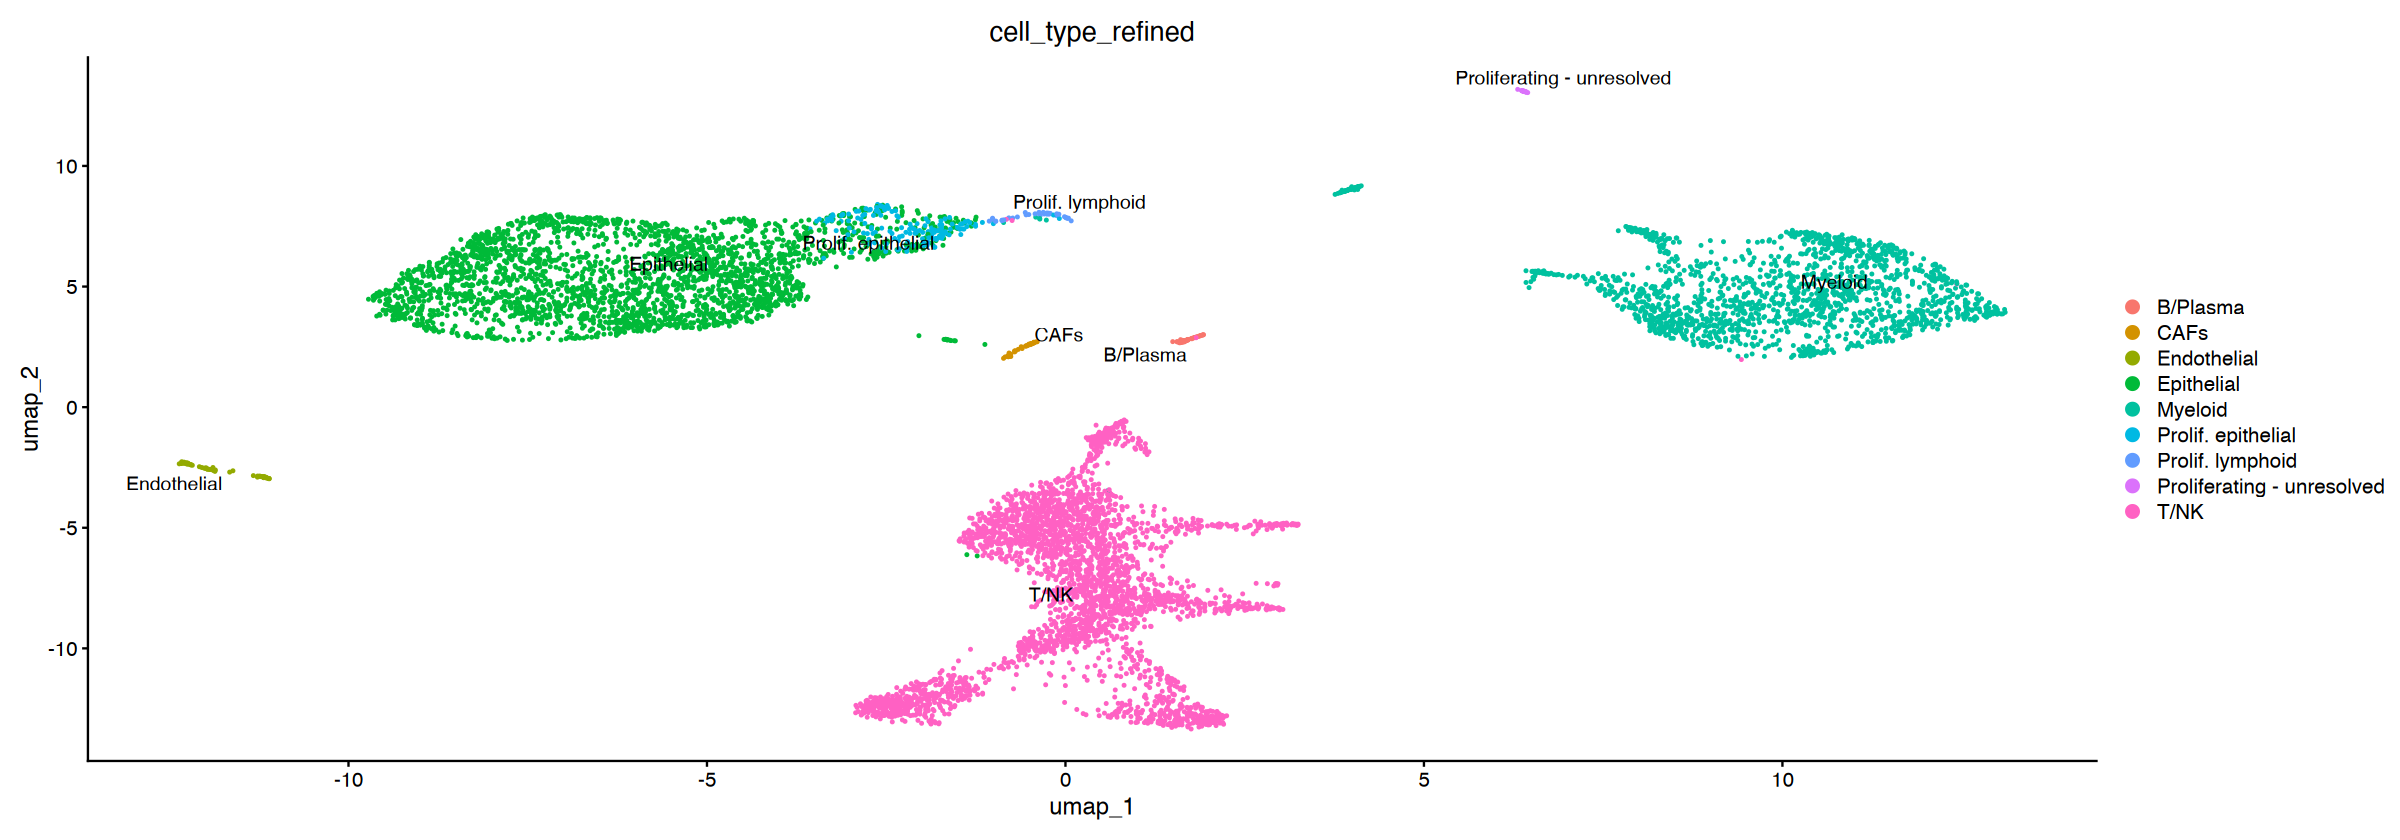

In [34]:
#Visualize the annotations

DimPlot(
  prechemo,
  reduction = "umap",
  group.by = "cell_type_refined",
  label = TRUE,
  repel = TRUE
)

Warning message:
“The following requested variables were not found: ACKR1, SFRP2”


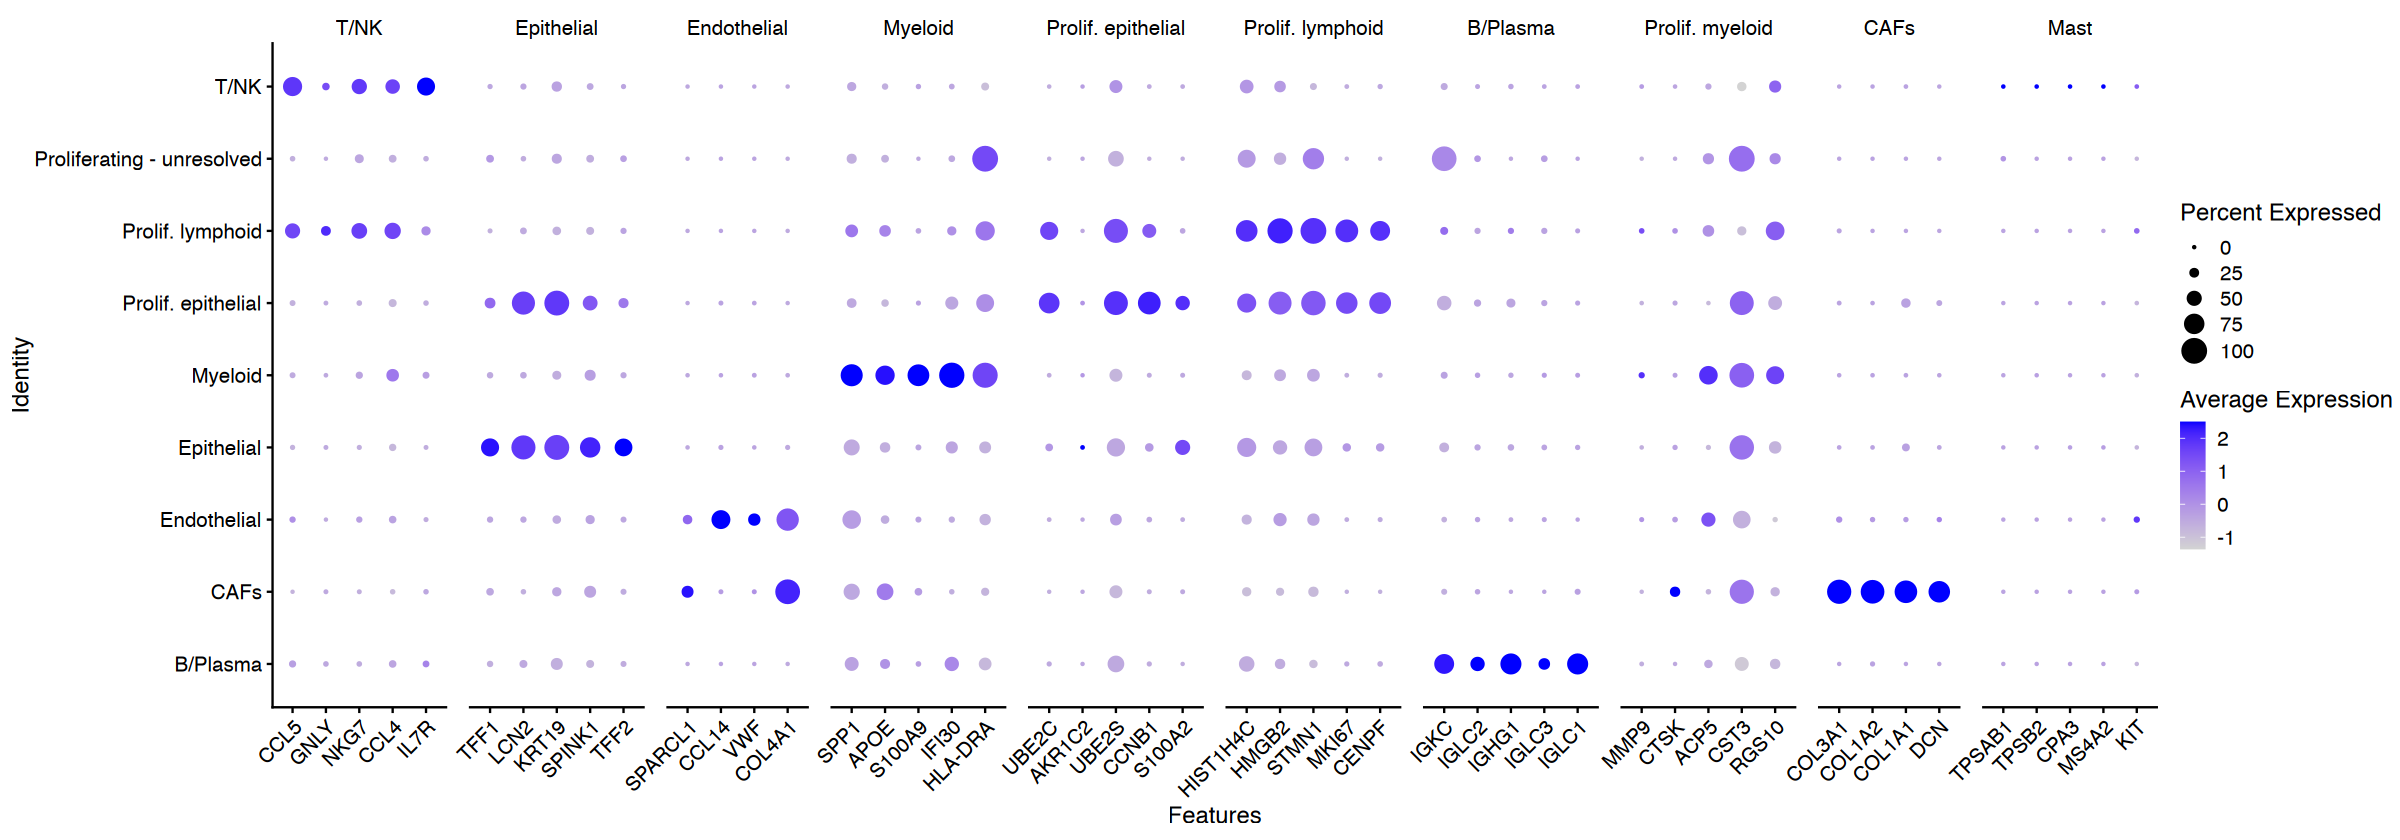

In [35]:
DefaultAssay(prechemo) <- "RNA"

DotPlot(
  prechemo,
  features = cell_type_markers,
  group.by = "cell_type_refined"
) + RotatedAxis()